Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


In [1]:
import pandas as pd
import numpy as np

from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df= pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [7]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [9]:
df.shape

(2443651, 9)

In [10]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [12]:
df[['category', 'isBestSeller']].isnull().sum()

category        0
isBestSeller    0
dtype: int64

In [13]:
crosstab = pd.crosstab(
    df['category'],
    df['isBestSeller']
)

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [14]:
crosstab.shape

(296, 2)

In [15]:
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [16]:
category_prop = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    normalize='index'
)

best_seller_rate = (
    category_prop[True]
    .sort_values(ascending=False)
)

best_seller_rate.head(10)

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

In [ ]:
#To identify categories where best-seller products are more prevalent, 
#the proportion of products with isBestSeller = True was calculated for each category. 
#The categories were then sorted in descending order based on this proportion. 
#The results show that some categories have a noticeably higher share of best-selling products than others, 
#indicating that best-seller status is not evenly distributed across product categories.

In [17]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(crosstab)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295


In [ ]:
#p-value = 0.0 < 0.05 we reject the null hypothesis.

In [18]:
import numpy as np

n = crosstab.values.sum()

min_dimension = min(crosstab.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.1222829439760564


In [ ]:
#Explanation
#n = total number of observations (products)
#min_dimension = min(296, 2) − 1 = 1



In [19]:
category_prop = pd.crosstab(
    df['category'],
    df['isBestSeller'],
    normalize='index'
)

top_categories = (
    category_prop[True]
    .sort_values(ascending=False)
    .head(15)
    .index
)

plot_data = category_prop.loc[top_categories]

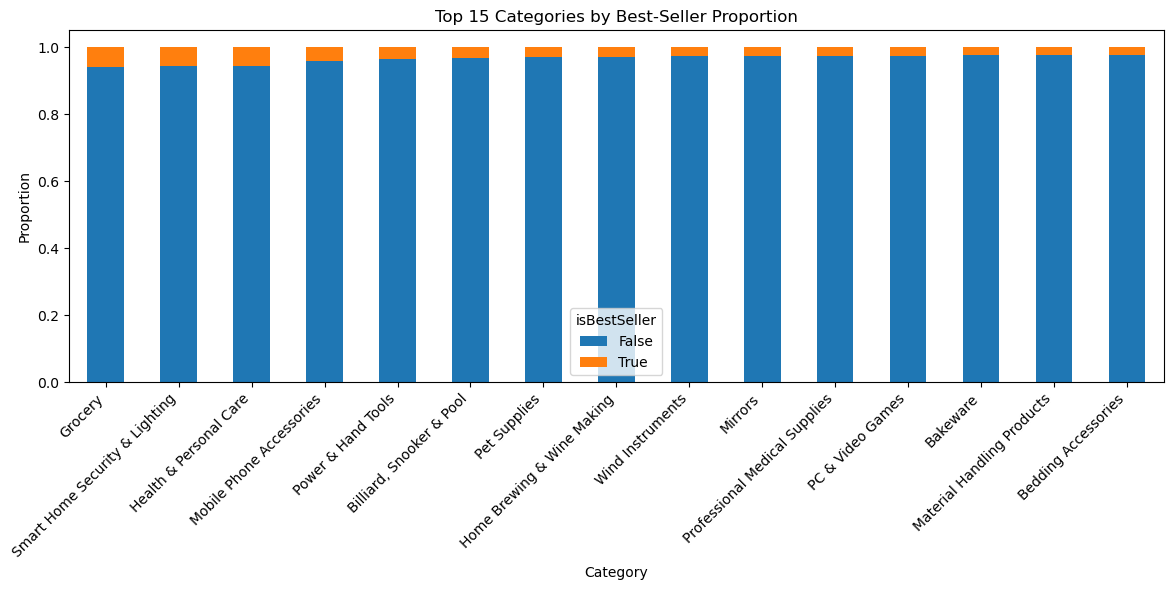

In [20]:
import matplotlib.pyplot as plt

plot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title('Top 15 Categories by Best-Seller Proportion')
plt.xlabel('Category')
plt.ylabel('Proportion')
plt.legend(title='isBestSeller')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

Crosstab Analysis

A contingency table was created between product category and best-seller status. To identify categories where best-seller products are more prevalent, the proportion of products marked as best-sellers was calculated within each category. The categories were then ranked according to this proportion. The results indicate that some categories have a noticeably higher concentration of best-selling products than others.

Chi-Square Test

A Chi-square test of independence was conducted to examine the relationship between product category and best-seller status. The test was statistically significant, χ²(295) = 36,540.20, p < 0.001, indicating that best-seller status is not independent of product category.

Cramér's V

Cramér's V was computed to measure the strength of the association between category and best-seller status. The resulting value indicates how strong the relationship is beyond statistical significance.

Run the Cramér's V code and send me the output; I'll help you write the final interpretation of the association strength.

In [21]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [22]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
]

print("Original shape:", df.shape)
print("Without outliers:", df_no_outliers.shape)

Original shape: (2443651, 9)
Without outliers: (2115963, 9)


In [23]:
df_no_outliers['price'].describe()

count    2.115963e+06
mean     2.340827e+01
std      2.051335e+01
min      0.000000e+00
25%      9.130000e+00
50%      1.599000e+01
75%      2.999000e+01
max      9.999000e+01
Name: price, dtype: float64

In [24]:
top20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[
    df_no_outliers['category'].isin(top20_categories)
]

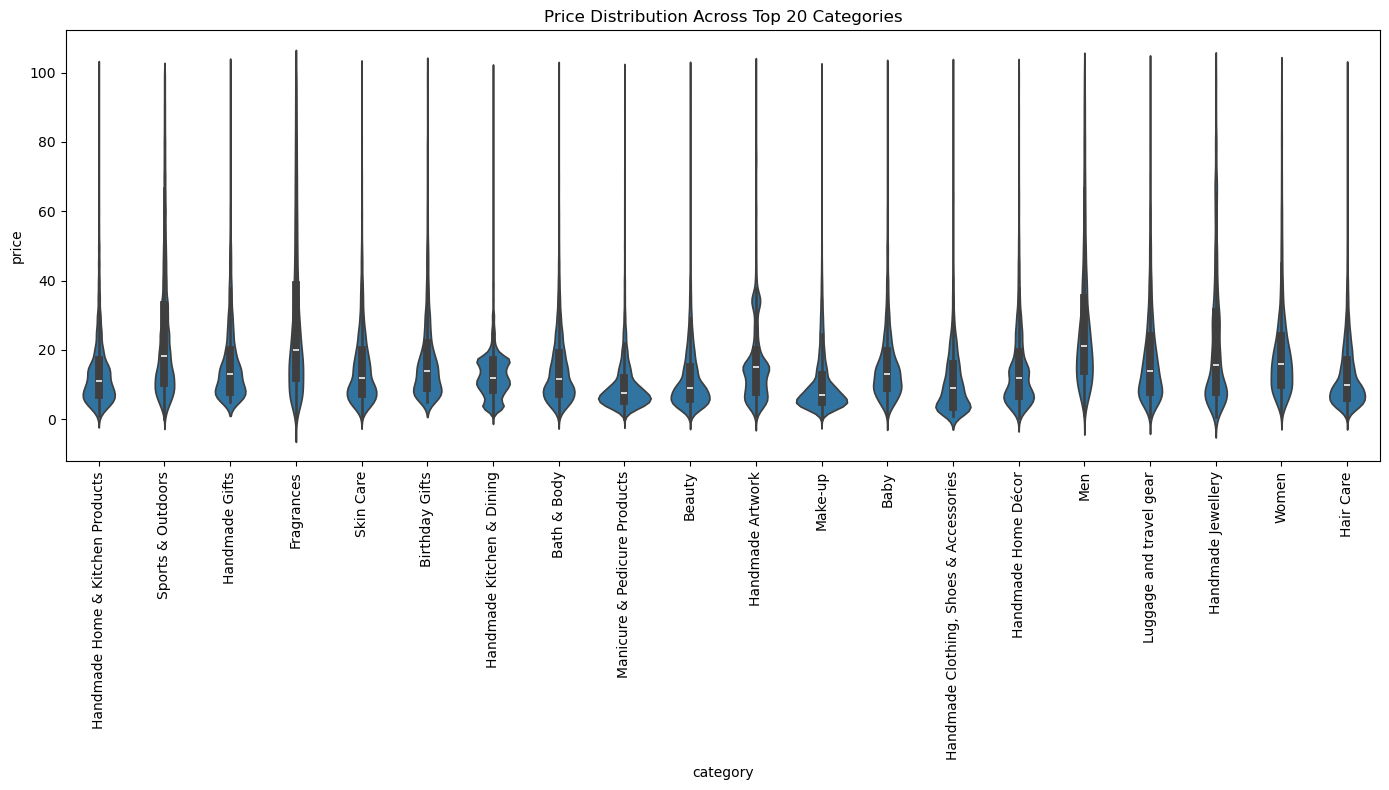

In [25]:
plt.figure(figsize=(14,8))

sns.violinplot(
    data=df_top20,
    x='category',
    y='price'
)

plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Categories')
plt.tight_layout()
plt.show()

In [26]:
median_prices = (
    df_no_outliers
    .groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [27]:
avg_prices_top10 = (
    df_no_outliers
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

In [28]:
top10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

avg_price_top10_count = (
    df_no_outliers[
        df_no_outliers['category'].isin(top10_categories)
    ]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

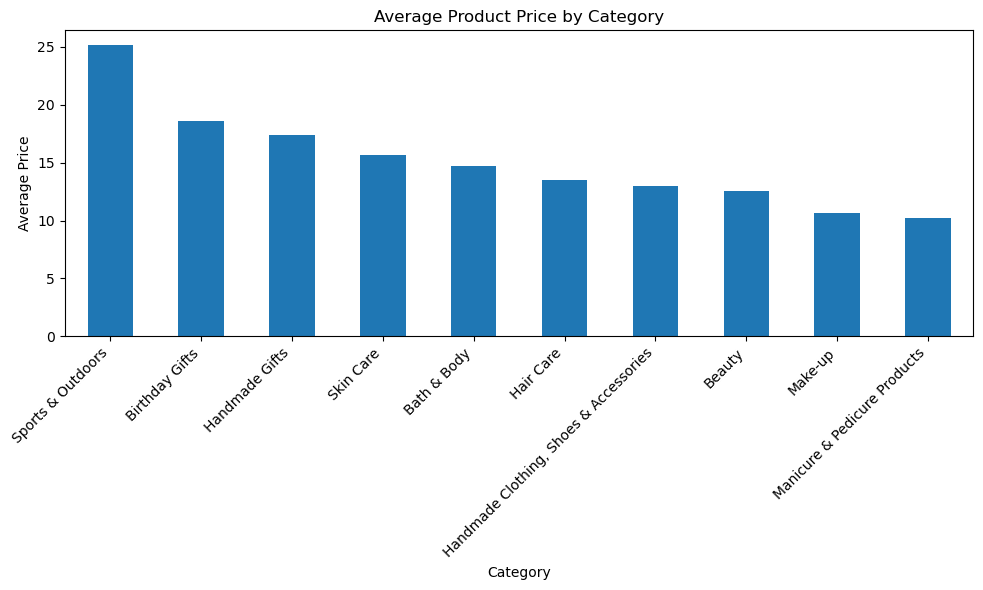

In [29]:
plt.figure(figsize=(10,6))

avg_price_top10_count.plot(kind='bar')

plt.title('Average Product Price by Category')
plt.ylabel('Average Price')
plt.xlabel('Category')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [32]:
df_no_outliers['stars'].describe()

count    2.115963e+06
mean     2.275402e+00
std      2.193863e+00
min      0.000000e+00
25%      0.000000e+00
50%      3.400000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [33]:
top10_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(10)
    .index
)

ratings_top10 = df_no_outliers[
    df_no_outliers['category'].isin(top10_categories)
]

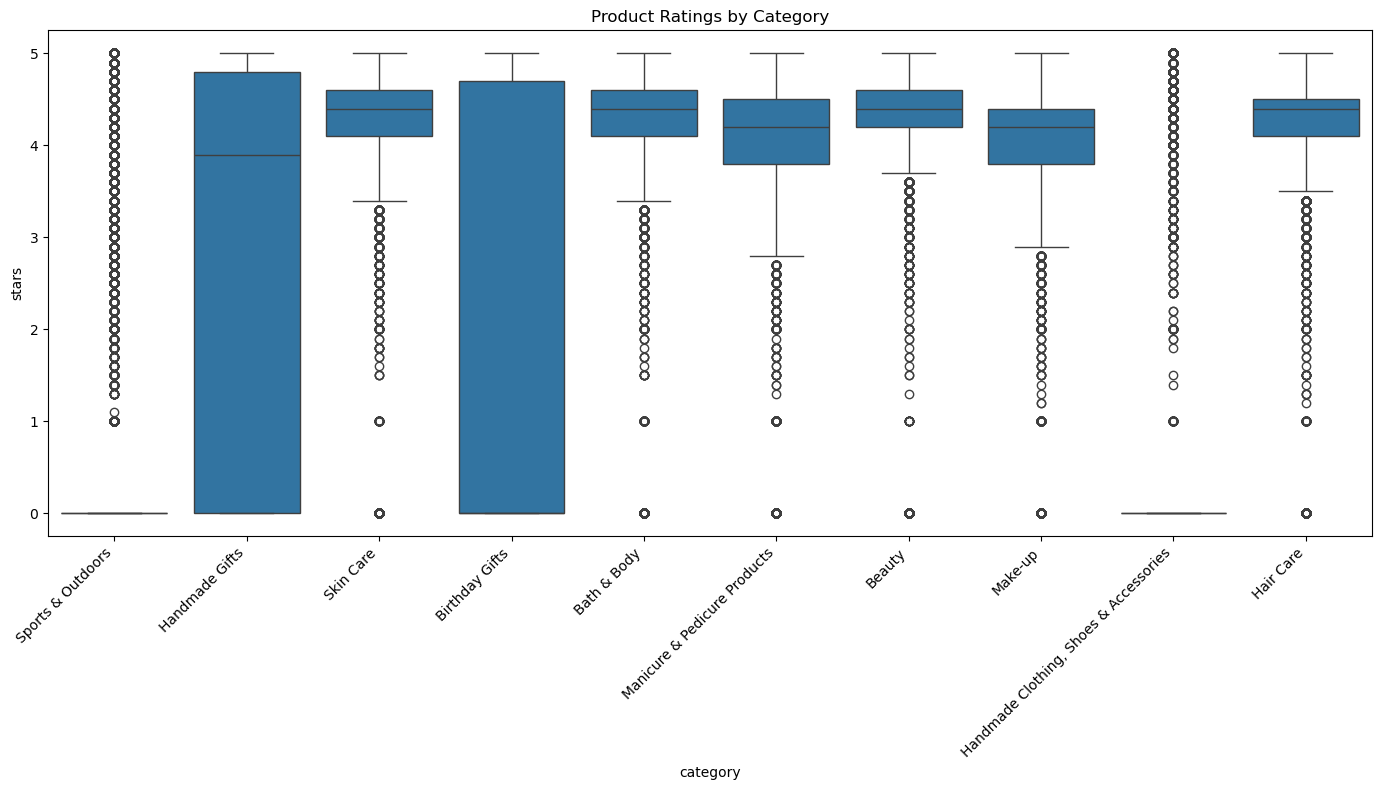

In [34]:
plt.figure(figsize=(14,8))

sns.boxplot(
    data=ratings_top10,
    x='category',
    y='stars'
)

plt.xticks(rotation=45, ha='right')
plt.title('Product Ratings by Category')
plt.tight_layout()
plt.show()

In [35]:
median_ratings = (
    df_no_outliers
    .groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

median_ratings.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

Results to Report

After running the notebook, report:

Category with highest median price
From median_prices.head(10)
Category with highest average price
From avg_prices.head(10)
Category with highest median rating
From median_ratings.head(10)

Paste those three outputs here, and I can help you write the final conclusions for the lab.

In [36]:
df_no_outliers.select_dtypes(include=['number']).columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [37]:
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])

print(f"Correlation between price and stars: {correlation:.4f}")

Correlation between price and stars: -0.0777


Interpretation

The Pearson correlation coefficient between price and stars is -0.0777.

This indicates:

A very weak negative correlation.
The relationship is so close to zero that it is practically negligible.
More expensive products tend to have slightly lower ratings on average, but the effect is extremely small.

<Axes: xlabel='stars', ylabel='price'>

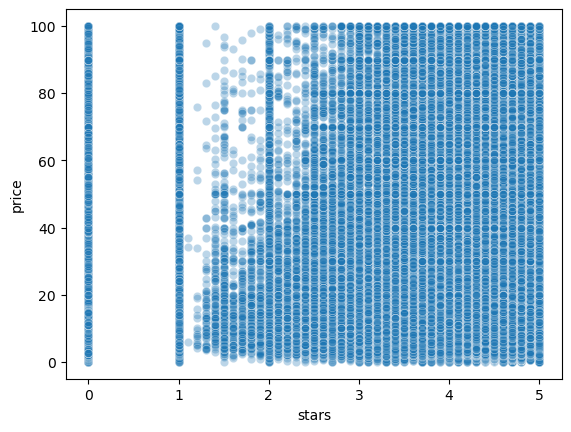

In [38]:
sns.scatterplot(
    data=df_no_outliers,
    x='stars',
    y='price',
    alpha=0.3
)

In [ ]:
#The scatter plot shows a broad dispersion of product prices across all rating levels. No clear upward or downward trend is visible, 
#supporting the finding of a negligible correlation between price and ratings.

In [40]:
numeric_cols = ['stars', 'reviews', 'price', 'boughtInLastMonth']

corr_matrix = df_no_outliers[numeric_cols].corr()

corr_matrix

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.083920,-0.077673,0.113994
reviews,0.083920,1.000000,-0.008498,0.105624
price,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.113994,0.105624,-0.059051,1.000000


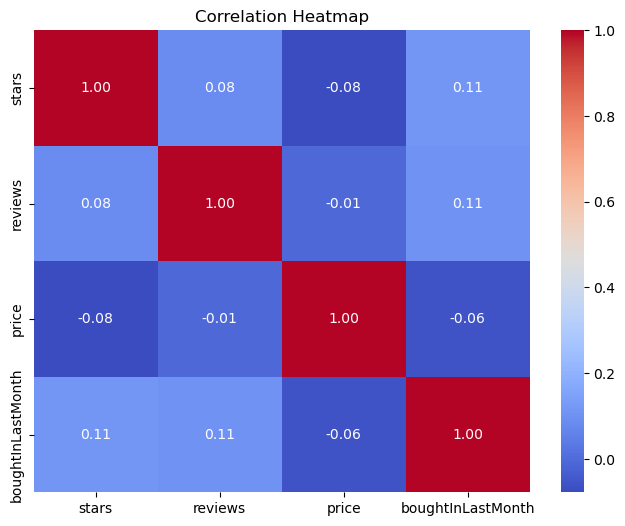

In [41]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

((array([-4.97420488, -4.79954158, -4.70525502, ...,  4.70525502,
          4.79954158,  4.97420488], shape=(2115963,)),
  array([ 0.  ,  0.  ,  0.  , ..., 99.99, 99.99, 99.99], shape=(2115963,))),
 (np.float64(18.50452591674651),
  np.float64(23.40826968619017),
  np.float64(0.9020702992645728)))

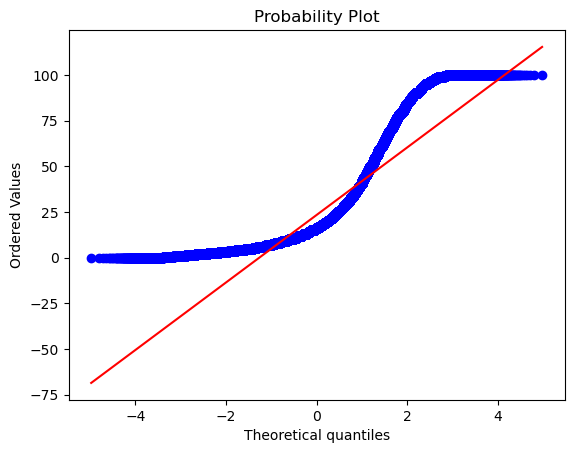

In [42]:
from scipy import stats

stats.probplot(
    df_no_outliers['price'],
    dist='norm',
    plot=plt
)

Final Conclusion

Analysis of the relationship between product prices and ratings revealed a negligible negative correlation (r = -0.0777). The scatter plot showed no meaningful linear trend, and the correlation heatmap confirmed the weak association. These findings suggest that product ratings are largely independent of price. Furthermore, the QQ plot indicated that product prices are not normally distributed, displaying noticeable skewness despite the removal of outliers.